In [15]:
import pandas as pd
import matplotlib.pyplot as plt

death_df = pd.read_csv("CommunityDistrictSingleYearAggregateCounts2022.csv")

In [16]:
death_df.head()

,Neighborhood,Community_District,Male,Female,Age<=28days,Age 1-12months,Age 1-4,Age 5-9,Age 10-14,Age 15-19,...,"Deaths due to assault(homicide),Hispanic","Deaths due to assault(homicide),Asian Non-Hispanic","Deaths due to assault(homicide),White Non-Hispanic","Deaths due to assault(homicide),Black Non-Hispanic","Deaths due to assault(homicide),Other race/ethnicity or not known","Other causes,Hispanic","Other causes,Asian Non-Hispanic","Other causes,White Non-Hispanic","Other causes,Black Non-Hispanic","Other causes,Other race/ethnicity or not known"
0,"Battery Park, Tribeca",101,99,82,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,10.0,20.0,6.0,NaN
1,"Greenwich Village, SOHO",102,204,194,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,6.0,12.0,81.0,6.0,NaN
2,Lower East Side,103,662,625,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,85.0,113.0,54.0,26.0,5.0
3,"Chelsea, Clinton",104,382,295,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,39.0,14.0,72.0,28.0,5.0
4,Midtown Business District,105,145,109,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5.0,NaN,38.0,5.0,5.0


In [17]:
death_df.columns.tolist()

['Neighborhood',
 'Community_District',
 'Male',
 'Female',
 'Age<=28days',
 'Age 1-12months',
 'Age 1-4',
 'Age 5-9',
 'Age 10-14',
 'Age 15-19',
 'Age 20-24',
 'Age 25-29',
 'Age 30-34',
 'Age 35-39',
 'Age 40-44',
 'Age 45-49',
 'Age 50-54',
 'Age 55-59',
 'Age 60-64',
 'Age 65-69',
 'Age 70-74',
 'Age 75-79',
 'Age 80-84',
 'Age 85+',
 'Age Unkown',
 'Male,Age<=28days',
 'Male,Age 1-12months',
 'Male,Age 1-4',
 'Male,Age 5-9',
 'Male,Age 10-14',
 'Male,Age 15-19',
 'Male,Age 20-24',
 'Male,Age 25-29',
 'Male,Age 30-34',
 'Male,Age 35-39',
 'Male,Age 40-44',
 'Male,Age 45-49',
 'Male,Age 50-54',
 'Male,Age 55-59',
 'Male,Age 60-64',
 'Male,Age 65-69',
 'Male,Age 70-74',
 'Male,Age 75-79',
 'Male,Age 80-84',
 'Male,Age 85+',
 'Male,Age Unkown',
 'Female,Age<=28days',
 'Female,Age 1-12months',
 'Female,Age 1-4',
 'Female,Age 5-9',
 'Female,Age 10-14',
 'Female,Age 15-19',
 'Female,Age 20-24',
 'Female,Age 25-29',
 'Female,Age 30-34',
 'Female,Age 35-39',
 'Female,Age 40-44',
 'Female,

In [19]:
death_df.columns = death_df.columns.str.strip()

In [27]:
death_df['Total_Deaths'] = death_df['Male'] + death_df['Female']
death_df = death_df.copy()

In [21]:
death_df[['Community_District', 'Male', 'Female', 'Total_Deaths']].head()

,Community_District,Male,Female,Total_Deaths
0,101,99,82,181
1,102,204,194,398
2,103,662,625,1287
3,104,382,295,677
4,105,145,109,254


In [22]:
death_df = death_df.copy()

In [24]:
deaths = death_df.groupby('Community_District')['Total_Deaths'].sum().reset_index()

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

census_df = pd.read_csv("Censuspopulationbycommunitydistrict2020.csv")

In [37]:
census_df.head()

,Community_District,Total_population,Total_persons_under_18
0,101,"78,390","12,775"
1,102,"92,445","8,587"
2,103,"163,141","18,955"
3,104,"131,351","11,444"
4,105,"63,600","5,982"


In [38]:
census_df.columns.tolist()

['Community_District', 'Total_population', 'Total_persons_under_18']

In [48]:
print(census_df['Total_population'].dtype)
print(census_df['Total_population'].head())

int64
0     78390
1     92445
2    163141
3    131351
4     63600
Name: Total_population, dtype: int64


In [52]:
census_df['Total_population'] = census_df['Total_population'].str.replace(',', '').astype(int)

AttributeError: Can only use .str accessor with string values, not integer

In [50]:
combined = pd.merge(
    census_df,
    deaths[['Community_District', 'Total_Deaths']],
    on='Community_District',
    how='inner'
)

In [51]:
combined['Death_Rate'] = (
    combined['Total_Deaths'] / combined['Total_population']
) * 1000

In [53]:
combined[['Community_District', 'Total_population', 'Total_Deaths', 'Death_Rate']]

,Community_District,Total_population,Total_Deaths,Death_Rate
0,101,78390,181,2.308968
1,102,92445,398,4.305263
2,103,163141,1287,7.888881
3,104,131351,677,5.154129
4,105,63600,254,3.993711
5,106,155614,743,4.774635
6,107,222129,1470,6.617776
7,108,231983,1449,6.246147
8,109,110458,644,5.830270
9,110,130440,948,7.267709


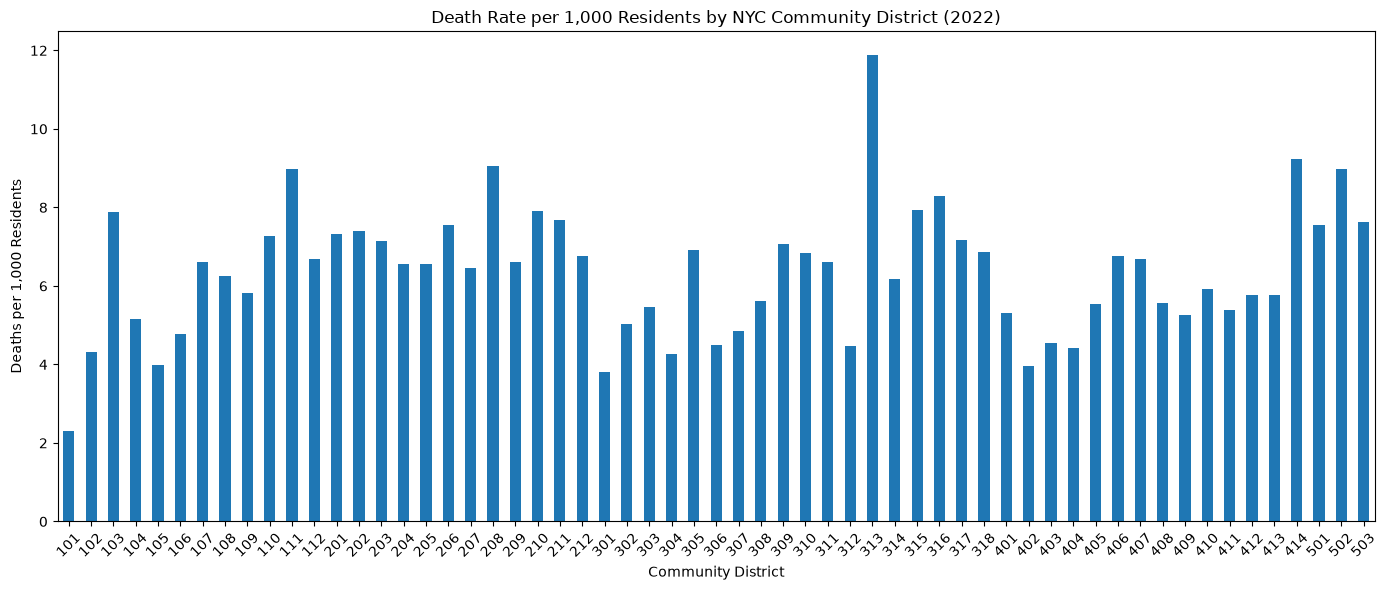

In [54]:
combined.plot(
    x='Community_District',
    y='Death_Rate',
    kind='bar',
    figsize=(14, 6),
    legend=False
)

plt.title('Death Rate per 1,000 Residents by NYC Community District (2022)')
plt.xlabel('Community District')
plt.ylabel('Deaths per 1,000 Residents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()